# Design of Experiments Notebook


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from ffd_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    build_mass_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    plot_screening_confirmation_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_mass_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


In [2]:
FD_I_LEVELS = {
    "A_flow_ratio": {-1: 1.00, 1: 1.05},
    "B_nozzle_temp": {-1: 220, 1: 230},
    "C_speed": {-1: 50, 1: 200},
    "D_line_width": {-1: 0.62, 1: 0.75},
    "E_layer_height": {-1: 0.12, 1: 0.18},
    "F_walls": {-1: 4, 1: 10},
}

FD_II_LEVELS = {
    "A_flow_ratio": {-1: 1.00, 1: 1.05},
    "B_nozzle_temp": {-1: 220, 1: 230},
    "C_speed": {-1: 50, 1: 100},
    "D_line_width": {-1: 0.62, 1: 0.75},
    "E_layer_height": {-1: 0.12, 1: 0.18},
}

DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## Step 1: Define DoE Run Matrices


### FD_I Screening Matrix With Wall Factors


In [3]:
fd_I_coded_df = create_fractional_factorial_design(include_walls=True)
fd_I_real_df = map_coded_to_real(fd_I_coded_df, FD_I_LEVELS)

fd_I_coded_display = fd_I_coded_df.rename(columns=DISPLAY_NAMES).reset_index()
fd_I_real_display = fd_I_real_df.rename(columns=DISPLAY_NAMES).reset_index()

display(fd_I_coded_display)
#display(fd_I_real_display)


,Run,Flow Ratio (-),Nozzle Temp (deg C),Print Speed (mm/s),Line Width (mm),Layer Height (mm),Walls (-)
0,1,-1,-1,-1,-1,1,1
1,2,-1,-1,-1,1,1,1
2,3,-1,-1,1,-1,1,-1
3,4,-1,-1,1,1,1,-1
4,5,-1,1,-1,-1,-1,1
5,6,-1,1,-1,1,-1,1
6,7,-1,1,1,-1,-1,-1
7,8,-1,1,1,1,-1,-1
8,9,1,-1,-1,-1,-1,-1
9,10,1,-1,-1,1,-1,-1


In [4]:
#style_low_high(fd_I_real_df, FD_I_LEVELS)


In [5]:
rep2 = randomized_second_run_order(random_state=123)
#rep2


### FD_II Screening Matrix Without Wall Factors


In [6]:
fd_II_coded_df = create_fractional_factorial_design(include_walls=False)
fd_II_real_df = map_coded_to_real(fd_II_coded_df, FD_II_LEVELS)

display(fd_II_coded_df)
#display(fd_II_real_df)


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height
Run,,,,,
1,-1,-1,-1,-1,1
2,-1,-1,-1,1,1
3,-1,-1,1,-1,1
4,-1,-1,1,1,1
5,-1,1,-1,-1,-1
6,-1,1,-1,1,-1
7,-1,1,1,-1,-1
8,-1,1,1,1,-1
9,1,-1,-1,-1,-1


### Extra Confirmation And Optimization Candidate Runs


#### 2-Factor 3-Level Candidate Matrix


In [7]:
# 2-parameter option: 9 runs.
# This is a full 3 x 3 grid and does not use Box-Behnken.
EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS = {
    "B_nozzle_temp": [225, 230, 235],
    "D_line_width": [0.62, 0.70, 0.80],
}

extra_run_9_real = pd.MultiIndex.from_product(
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.values(),
    names=EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.keys(),
).to_frame(index=False)
extra_run_9_real.index += 1
extra_run_9_real.index.name = "Run"

display(extra_run_9_real)


,B_nozzle_temp,D_line_width
Run,,
1,225,0.62
2,225,0.70
3,225,0.80
4,230,0.62
5,230,0.70
6,230,0.80
7,235,0.62
8,235,0.70
9,235,0.80


#### 3-Factor Box-Behnken Candidate Matrix


In [8]:
# 3-parameter option: 15 runs.
# Box-Behnken needs exactly 3 factors, so keep layer height included here.

IRONING_FIXED_SETTINGS = {
    "flow_ratio": 1.05,
    "volumetric_speed": 8, #mm3/s,
}

EXTRA_RUN_BOX_BEHNKEN_LEVELS = {
    "B_nozzle_temp": {-1: 225, 0: 230, 1: 235},
    "D_line_width": {-1: 0.62, 0: 0.70, 1: 0.80},
    "E_layer_height": {-1: 0.10, 0: 0.12, 1: 0.14},
}

extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    center_repeats=3,
)

display(extra_run_15_coded)
display(extra_run_15_real)


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,0,-1,-1
2,0,-1,1
3,0,1,-1
4,0,1,1
5,-1,0,-1
6,-1,0,1
7,1,0,-1
8,1,0,1
9,-1,-1,0


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,230,0.62,0.10
2,230,0.62,0.14
3,230,0.80,0.10
4,230,0.80,0.14
5,225,0.70,0.10
6,225,0.70,0.14
7,235,0.70,0.10
8,235,0.70,0.14
9,225,0.62,0.12


### Ironing Trial Matrix


In [9]:
IRONING_FIXED_SETTINGS = {
    "C_ironing_line_spacing_mm": 0.15,
    "E_layer_height": 0.12,
    "F_line_width_mm": 0.62,
}

IRONING_LEVELS = {
    "A_flow_ratio": {-1: 0.99, 0: 1.00, 1: 1.01},
    "B_nozzle_temp_C": {-1: 215, 0: 220, 1: 225},
    "C_ironing_flow_percent": {-1: 0, 0: 1, 1: 2},
    "D_ironing_speed_mm_s": {-1: 30, 0: 45, 1: 60},
}

# 4-factor half-fraction screening design plus center runs.
# Generator: D = A*B*C, so the defining relation is I = A*B*C*D.
# This gives 8 factorial runs + 3 center repeats = 11 runs total.
# Main effects are not aliased with two-factor interactions, but two-factor
# interactions are aliased in pairs: AB=CD, AC=BD, AD=BC.
ironing_base_factors = [
    "A_flow_ratio",
    "B_nozzle_temp_C",
    "C_ironing_flow_percent",
]
ironing_factorial_coded = pd.MultiIndex.from_product(
    [[-1, 1], [-1, 1], [-1, 1]],
    names=ironing_base_factors,
).to_frame(index=False)
ironing_factorial_coded["D_ironing_speed_mm_s"] = (
    ironing_factorial_coded["A_flow_ratio"]
    * ironing_factorial_coded["B_nozzle_temp_C"]
    * ironing_factorial_coded["C_ironing_flow_percent"]
)
ironing_factorial_coded = ironing_factorial_coded[list(IRONING_LEVELS)]

ironing_center_coded = pd.DataFrame([
    {factor: 0 for factor in IRONING_LEVELS}
    for _ in range(3)
])

ironing_coded = pd.concat(
    [ironing_factorial_coded, ironing_center_coded],
    ignore_index=True,
)
ironing_coded.index += 1
ironing_coded.index.name = "Run"

ironing_real = map_coded_to_real(ironing_coded, IRONING_LEVELS)
for setting, value in IRONING_FIXED_SETTINGS.items():
    ironing_real[setting] = value

print(f"Ironing design runs: {len(ironing_coded)}")
display(ironing_coded)
display(ironing_real)


Ironing design runs: 11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s
Run,,,,
1,-1,-1,-1,-1
2,-1,-1,1,1
3,-1,1,-1,1
4,-1,1,1,-1
5,1,-1,-1,1
6,1,-1,1,-1
7,1,1,-1,-1
8,1,1,1,1
9,0,0,0,0


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm
Run,,,,,,,
1,0.99,215,0,30,0.15,0.12,0.62
2,0.99,215,2,60,0.15,0.12,0.62
3,0.99,225,0,60,0.15,0.12,0.62
4,0.99,225,2,30,0.15,0.12,0.62
5,1.01,215,0,60,0.15,0.12,0.62
6,1.01,215,2,30,0.15,0.12,0.62
7,1.01,225,0,30,0.15,0.12,0.62
8,1.01,225,2,60,0.15,0.12,0.62
9,1.00,220,1,45,0.15,0.12,0.62


## Step 2: Enter Measurements And Plot Mass Results


### FD_I Mass Measurements


In [10]:
fd_I_mass_measurements_g, fd_I_mass_columns = build_mass_measurements(
    FD_I_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
fd_I_repeat_mass_measurements_g, fd_I_repeat_mass_columns = build_repeat_mass_measurements(
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
)

display(fd_I_mass_measurements_g[["run", *fd_I_mass_columns, "mass_mean_g", "mass_std_g"]])
display(fd_I_repeat_mass_measurements_g[["run", *fd_I_repeat_mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,R1,13.681,13.7,NaN
1,R2,13.657,13.7,NaN
2,R3,13.622,13.6,NaN
3,R4,13.594,13.6,NaN
4,R5,13.796,13.8,NaN
5,R6,13.843,13.8,NaN
6,R7,13.972,14.0,NaN
7,R8,13.973,14.0,NaN
8,R9,14.480,14.5,NaN
9,R10,14.541,14.5,NaN


,run,mass_1_g,mass_mean_g,mass_std_g
0,R2.2,13.795,13.8,NaN
1,R9.2,14.555,14.6,NaN
2,R12.2,14.628,14.6,NaN


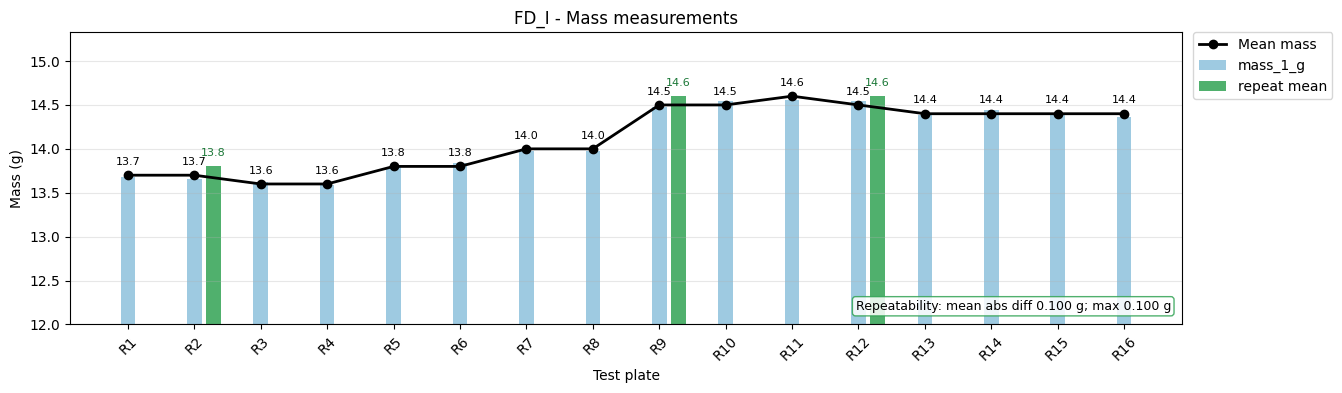

In [11]:
plot_mass_measurements(
    fd_I_mass_measurements_g,
    fd_I_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I",
    repeat_measurements_g=fd_I_repeat_mass_measurements_g,
)


#### FD_I Repeatability From Repeated Prints


In [12]:
fd_I_repeatability = calculate_repeatability(
    fd_I_mass_measurements_g,
    fd_I_repeat_mass_measurements_g,
)

display(fd_I_repeatability)
print(
    "Mean absolute repeat difference:",
    f"{fd_I_repeatability['abs_difference_g'].mean():.3f} g",
)


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,difference_g,abs_difference_g,difference_percent
0,R2.2,R2,13.7,13.8,0.1,0.1,0.73
1,R9.2,R9,14.5,14.6,0.1,0.1,0.69
2,R12.2,R12,14.5,14.6,0.1,0.1,0.69


Mean absolute repeat difference: 0.100 g


### FD_II Mass Measurements - RR Rectilinear Pattern


In [13]:
mass_measurements_g, mass_columns = build_mass_measurements(FD_II_MASS_MEASUREMENTS_G)

display(mass_measurements_g[["run", *mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,RR1,84.536,84.5,NaN
1,RR2,84.550,84.6,NaN
2,RR3,84.349,84.3,NaN
3,RR4,84.496,84.5,NaN
4,RR5,85.314,85.3,NaN
5,RR6,84.483,84.5,NaN
6,RR7,85.337,85.3,NaN
7,RR8,84.320,84.3,NaN
8,RR9,88.351,88.4,NaN
9,RR10,87.760,87.8,NaN


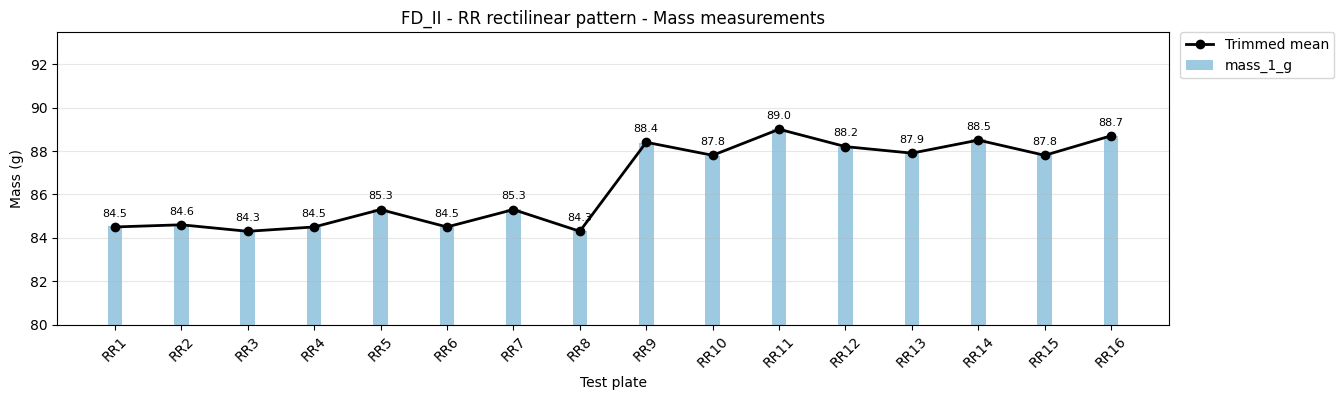

In [14]:
plot_mass_measurements(
    mass_measurements_g,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II - RR rectilinear pattern",
)


### FD_II Mass Measurements - RC Concentric Pattern


In [15]:
fd_II_concentric_mass_measurements_g, fd_II_concentric_mass_columns = build_mass_measurements(
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
    run_labels=FD_II_CONCENTRIC_RUN_LABELS,
)

display(fd_II_concentric_mass_measurements_g[[
    "run",
    *fd_II_concentric_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,RC1,83.862,83.9,NaN
1,RC2,NaN,NaN,NaN
2,RC3,NaN,NaN,NaN
3,RC4,NaN,NaN,NaN
4,RC5,NaN,NaN,NaN
5,RC6,NaN,NaN,NaN
6,RC7,NaN,NaN,NaN
7,RC8,NaN,NaN,NaN
8,RC9,NaN,NaN,NaN
9,RC10,NaN,NaN,NaN


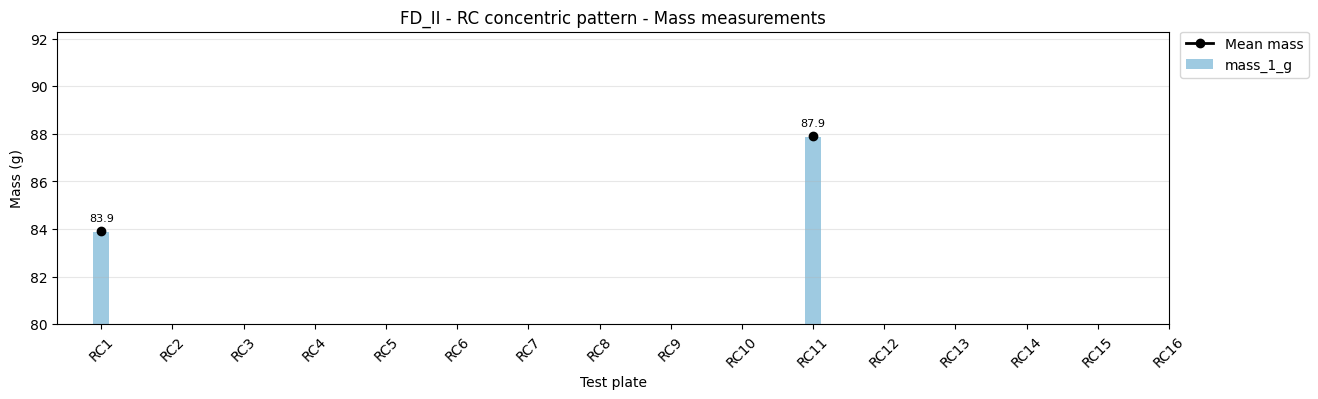

In [16]:
plot_mass_measurements(
    fd_II_concentric_mass_measurements_g,
    fd_II_concentric_mass_columns,
    y_min=80,
    mean_label="Mean mass",
    experiment="FD_II - RC concentric pattern",
)


#### FD_II Repeatability Placeholder


In [17]:
# TODO: Build FD_II repeat measurements and calculate repeatability.
# fd_II_repeatability = calculate_repeatability(
#     mass_measurements_g,
#     fd_II_repeat_mass_measurements_g,
# )
# display(fd_II_repeatability)


### Extra-Run Mass Measurements


,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_mean_g,mass_std_g
0,LD,35.585,35.710,NaN,None,35.6,0.088388
1,HD,NaN,NaN,NaN,None,NaN,NaN
2,E1,86.642,87.034,86.975,None,86.9,0.211358
3,E2,NaN,NaN,NaN,None,NaN,NaN
4,E3,NaN,NaN,NaN,None,NaN,NaN
5,E4,NaN,NaN,NaN,None,NaN,NaN
6,E5,NaN,NaN,NaN,None,NaN,NaN
7,E6,NaN,NaN,NaN,None,NaN,NaN


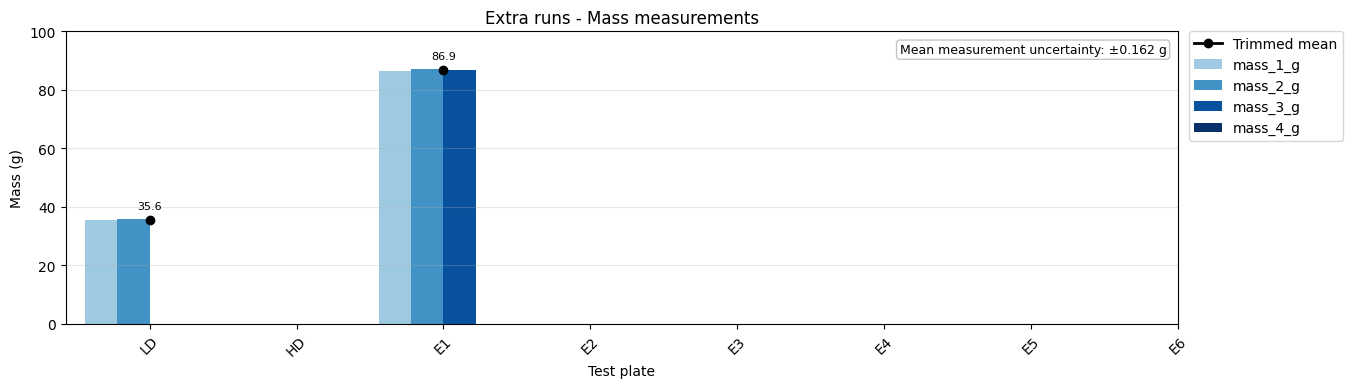

In [18]:
extra_run_mass_measurements_g, extra_run_mass_columns = build_mass_measurements(
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    run_labels=EXTRA_RUN_LABELS,
)

display(extra_run_mass_measurements_g[[
    "run",
    *extra_run_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    extra_run_mass_measurements_g,
    extra_run_mass_columns,
    y_min=0,
    y_max=100,
    mean_label="Trimmed mean",
    experiment="Extra runs",
)

### Box-Behnken Mass Measurements From New Scale


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,B1,89.090,89.100,89.1,0.007071
1,B2,89.015,89.022,89.0,0.004950
2,B3,88.986,88.996,89.0,0.007071
3,B4,89.171,89.183,89.2,0.008485
4,B5,89.313,89.316,89.3,0.002121
5,B6,89.789,89.796,89.8,0.004950
6,B7,89.720,89.730,89.7,0.007071
7,B8,89.306,89.312,89.3,0.004243
8,B9,88.868,88.863,88.9,0.003536
9,B10,89.093,89.105,89.1,0.008485


,runs_with_repeated_measurements,mean_measurement_std_g,rms_measurement_uncertainty_g,max_measurement_std_g
0,15,0.0058,0.0063,0.0092


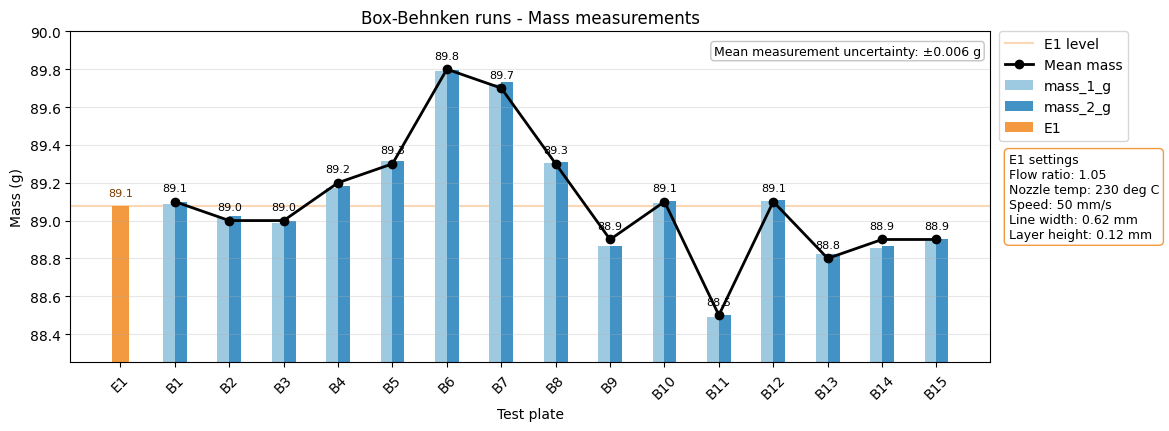

In [19]:
box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
)

display(box_behnken_mass_measurements_g[[
    "run",
    *box_behnken_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

box_behnken_repeated_measurements_g = box_behnken_mass_measurements_g.dropna(
    subset=["mass_std_g"]
)
box_behnken_measurement_uncertainty_summary = pd.DataFrame([{
    "runs_with_repeated_measurements": len(box_behnken_repeated_measurements_g),
    "mean_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].mean(),
    "rms_measurement_uncertainty_g": (
        (box_behnken_repeated_measurements_g["mass_std_g"] ** 2).mean() ** 0.5
    ),
    "max_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].max(),
}])
display(box_behnken_measurement_uncertainty_summary.round(4))

e1_reference_mass_g = 89.077

plot_mass_measurements(
    box_behnken_mass_measurements_g,
    box_behnken_mass_columns,
    y_min=88.25,
    y_max=90,
    mean_label="Mean mass",
    experiment="Box-Behnken runs",
    reference_mass_g=e1_reference_mass_g,
    reference_label="E1",
    reference_details=(
        "E1 settings\n"
        "Flow ratio: 1.05\n"
        "Nozzle temp: 230 deg C\n"
        "Speed: 50 mm/s\n"
        "Line width: 0.62 mm\n"
        "Layer height: 0.12 mm"
    ),
)


### FD_II and Box-Behnken Combined Mass Comparison


This plot combines the FD_II RR runs and Box-Behnken runs because they use the same specimen geometry. Only runs with a mean mass above 80 g are included. Box-Behnken error bars show the standard deviation of its repeated scale measurements where available.


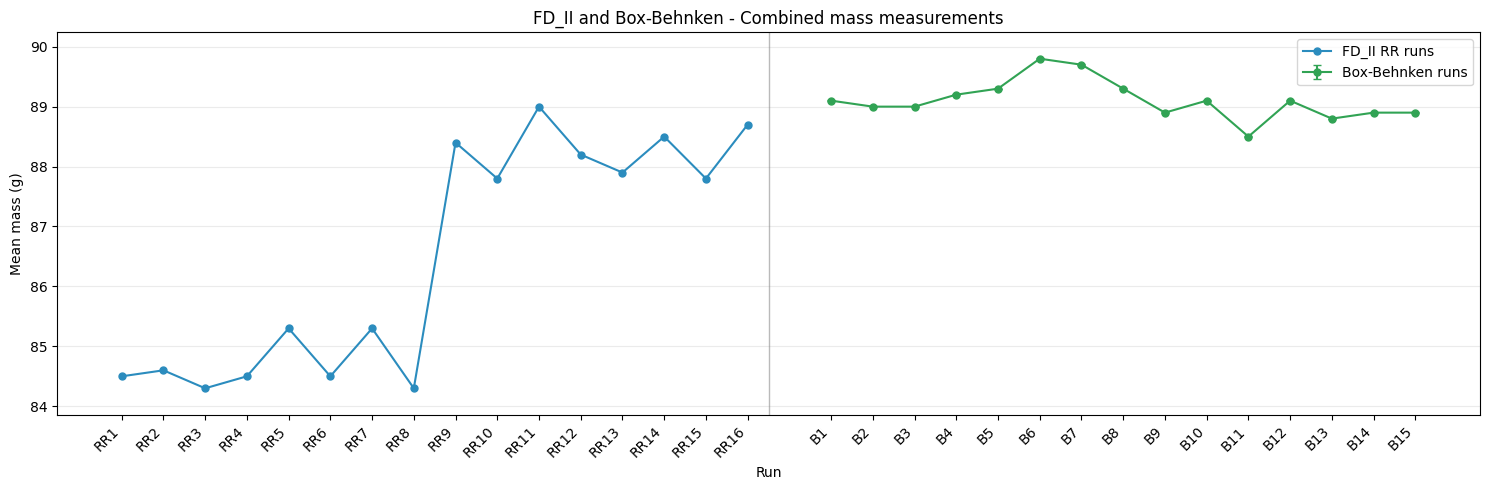

In [20]:
plot_combined_mass_measurement_sets(
    {
        "FD_II RR runs": mass_measurements_g,
        "Box-Behnken runs": box_behnken_mass_measurements_g,
    },
    minimum_mass=80,
    experiment="FD_II and Box-Behnken",
)


### Ironing-Run Mass Measurement Placeholders


Ideal mass for ironing runs: 9.48 g


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,I1,9.452,None,9.45,NaN
1,I2,9.623,None,9.62,NaN
2,I3,9.477,None,9.48,NaN
3,I4,9.537,None,9.54,NaN
4,I5,9.551,None,9.55,NaN
5,I6,9.678,None,9.68,NaN
6,I7,9.558,None,9.56,NaN
7,I8,9.718,None,9.72,NaN
8,I9,9.500,None,9.50,NaN
9,I10,9.477,None,9.48,NaN


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
7,I8.2,9.712,None,9.71,NaN


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,difference_g,abs_difference_g,difference_percent
0,I8.2,I8,9.72,9.71,-0.01,0.01,-0.1


Mean absolute repeat difference: 0.010 g


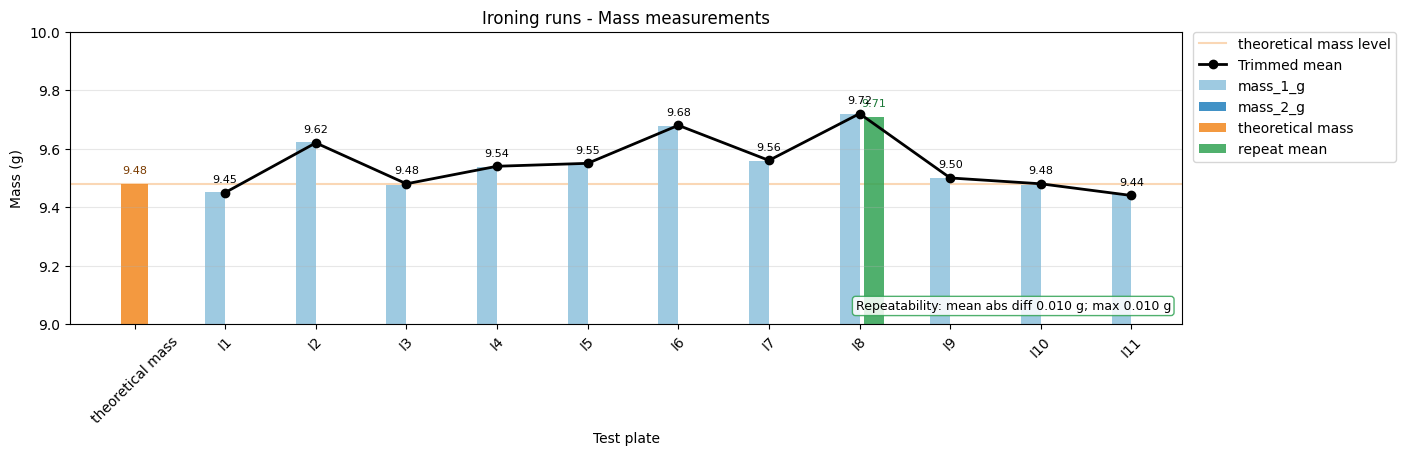

In [21]:
from ffd_utils import ideal_mass_g


ironing_mass_measurements_g, ironing_mass_columns = build_mass_measurements(
    IRONING_MASS_MEASUREMENTS_G,
    run_labels=IRONING_RUN_LABELS,
    mean_round_digits=2,
)
ironing_repeat_mass_measurements_g, ironing_repeat_mass_columns = (
    build_repeat_mass_measurements(
        IRONING_REPEAT_MASS_MEASUREMENTS_G,
        mean_round_digits=2,
    )
)
ironing_repeatability = calculate_repeatability(
    ironing_mass_measurements_g,
    ironing_repeat_mass_measurements_g,
)

volume_ironing_mm3 = 60 * 30 * 4.02
ideal_mass_ironing_g = ideal_mass_g(volume_ironing_mm3, density_g_cm3=1.31)
print(f"Ideal mass for ironing runs: {ideal_mass_ironing_g:.2f} g")

display(ironing_mass_measurements_g[[
    "run",
    *ironing_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])
display(
    ironing_repeat_mass_measurements_g.dropna(subset=["mass_mean_g"])[[
        "run",
        *ironing_repeat_mass_columns,
        "mass_mean_g",
        "mass_std_g",
    ]]
)
display(ironing_repeatability)
if not ironing_repeatability.empty:
    print(
        "Mean absolute repeat difference:",
        f"{ironing_repeatability['abs_difference_g'].mean():.3f} g",
    )

plot_mass_measurements(
    ironing_mass_measurements_g,
    ironing_mass_columns,
    y_min=9,
    y_max=10,
    mean_label="Trimmed mean",
    experiment="Ironing runs",
    repeat_measurements_g=ironing_repeat_mass_measurements_g,
    repeat_bar_offset=0.16,
    reference_mass_g=ideal_mass_ironing_g,
    reference_label="theoretical mass",
    value_digits=2,
)


### Ironing Confirmation Runs


IA and IB are additional runs at mixed coded levels. They are appended to an augmented ironing matrix and included in the mass-quality/desirability comparison. The original I1-I11 rows are still used alone to estimate the planned half-fraction effects, while IA and IB remain independent checks of those estimates.


In [22]:
ironing_confirmation_runs = pd.DataFrame(IRONING_CONFIRMATION_RUNS)
display(ironing_confirmation_runs)


,run,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,quality_score,has_stringing
0,IA,1.01,220,2,60,9.650,2.5,False
1,IB,1.01,220,2,45,9.627,8.0,True


### Ironing Visual Quality Measurements


Blob count and stringing are treated as a second response. The visual quality score is calculated as `blob count + stringing penalty`; lower values are better. The default stringing penalty is 5, so one stringing observation is treated like five additional blobs. Change `STRINGING_PENALTY` if this weighting feels too strong or too weak.


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I1,7,False,0,7
1,I2,11,False,0,11
2,I3,2,False,0,2
3,I4,3,False,0,3
4,I5,6,False,0,6
5,I6,10,True,5,15
6,I7,1,False,0,1
7,I8,1,False,0,1
8,I9,2,False,0,2
9,I10,2,False,0,2


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I8.2,2,False,0,2


,run,repeat_quality_score,original_run,original_quality_score,difference,abs_difference
0,I8.2,2,I8,1,1,1


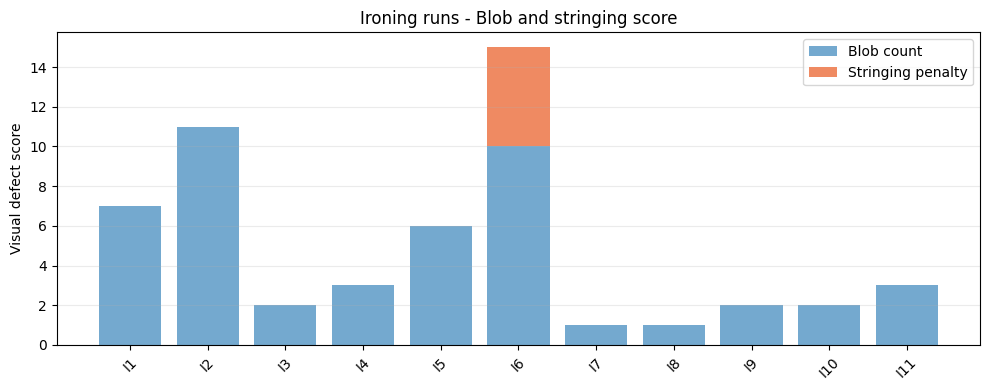

In [23]:
STRINGING_PENALTY = 5

ironing_quality_table = build_ironing_quality_table(
    IRONING_BLOB_COUNTS,
    run_labels=IRONING_RUN_LABELS,
    stringing_runs=IRONING_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)
ironing_repeat_quality_table = build_ironing_quality_table(
    IRONING_REPEAT_BLOB_COUNTS,
    stringing_runs=IRONING_REPEAT_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)

ironing_quality_repeatability = calculate_score_repeatability(
    ironing_quality_table,
    ironing_repeat_quality_table,
    score_col="quality_score",
)

display(ironing_quality_table)
display(ironing_repeat_quality_table)
display(ironing_quality_repeatability)
plot_quality_counts(ironing_quality_table, experiment="Ironing runs")


In [24]:
ironing_design_tradeoff = build_mass_quality_tradeoff(
    ironing_mass_measurements_g,
    ironing_quality_table,
    target_mass_g=ideal_mass_ironing_g,
    mass_weight=0.5,
    quality_weight=0.5,
)

ironing_confirmation_tradeoff = ironing_confirmation_runs[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].copy()
ironing_confirmation_tradeoff["blob_count"] = pd.NA

ironing_mass_quality_tradeoff = pd.concat(
    [ironing_design_tradeoff, ironing_confirmation_tradeoff],
    ignore_index=True,
    sort=False,
)

display(ironing_mass_quality_tradeoff[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].round(3))


,run,mass_mean_g,quality_score,has_stringing
0,I10,9.480,2.0,False
1,I3,9.480,2.0,False
2,I9,9.500,2.0,False
3,I11,9.440,3.0,False
4,I7,9.560,1.0,False
5,I4,9.540,3.0,False
6,I1,9.450,7.0,False
7,I5,9.550,6.0,False
8,I8,9.720,1.0,False
9,I2,9.620,11.0,False


## Step 3: Analyze Effects, Interactions, And Models


### FD_I Screening Analysis


#### FD_I Main-Effect Estimates


In [25]:
mass_result_matrix_I = build_result_matrix(
    fd_I_coded_df,
    fd_I_mass_measurements_g,
    response="mass_mean_g",
)
mass_result_matrix_I


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,F_walls,mass_mean_g
Run,,,,,,,
1,-1,-1,-1,-1,1,1,13.7
2,-1,-1,-1,1,1,1,13.7
3,-1,-1,1,-1,1,-1,13.6
4,-1,-1,1,1,1,-1,13.6
5,-1,1,-1,-1,-1,1,13.8
6,-1,1,-1,1,-1,1,13.8
7,-1,1,1,-1,-1,-1,14.0
8,-1,1,1,1,-1,-1,14.0
9,1,-1,-1,-1,-1,-1,14.5


In [26]:
main_effect_df_I = compute_main_effects(mass_result_matrix_I)
main_effect_df_I


,Effect,Main effect
0,A_flow_ratio,0.6875
1,B_nozzle_temp,0.0625
2,C_speed,0.0375
3,D_line_width,-0.0125
4,E_layer_height,-0.1875
5,F_walls,-0.0125


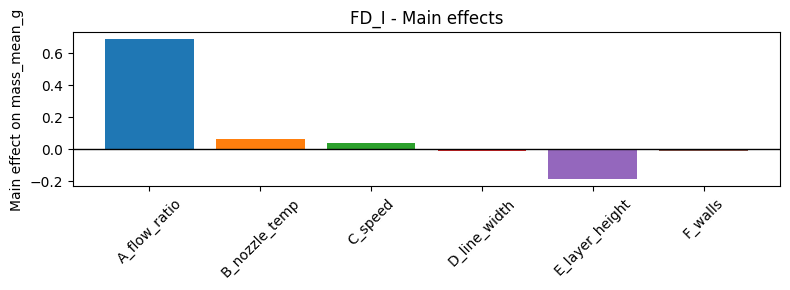

In [27]:
plot_main_effects_bar(
    main_effect_df_I,
    response="mass_mean_g",
    experiment="FD_I",
)


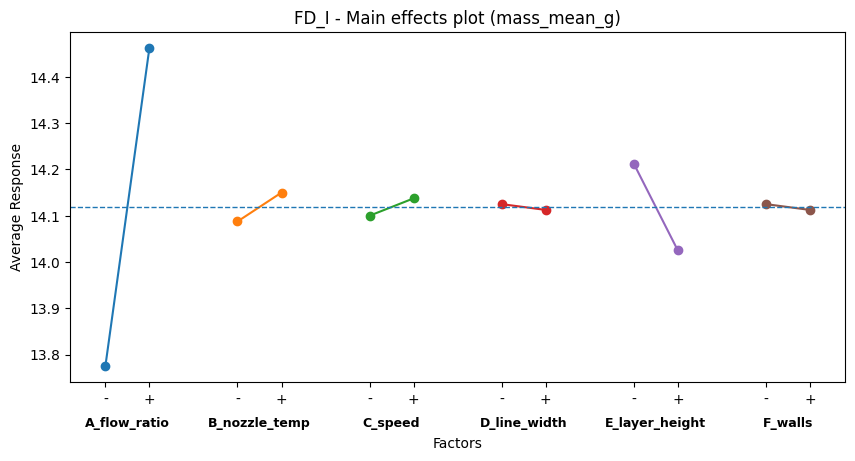

In [28]:
plot_main_effects_line(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)


#### FD_I Aliased Interaction Estimates


In [29]:
mass_interaction_matrix = add_interactions(mass_result_matrix_I)

#mass_interaction_matrix


In [30]:
FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

interaction_effects_I = compute_interaction_effects(
    mass_result_matrix_I,
    response="mass_mean_g",
    generators=FD_I_GENERATORS,
)

interaction_effects_I


,Interaction,Alias / generator note,Effect
7,B_nozzle_temp x E_layer_height,,0.6875
11,C_speed x F_walls,,0.6875
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-0.1875
8,B_nozzle_temp x F_walls,,-0.0875
10,C_speed x E_layer_height,,-0.0875
3,A_flow_ratio x E_layer_height,,0.0625
5,B_nozzle_temp x C_speed,,0.0625
14,E_layer_height x F_walls,,0.0625
4,A_flow_ratio x F_walls,,0.0375
2,A_flow_ratio x D_line_width,,-0.0125


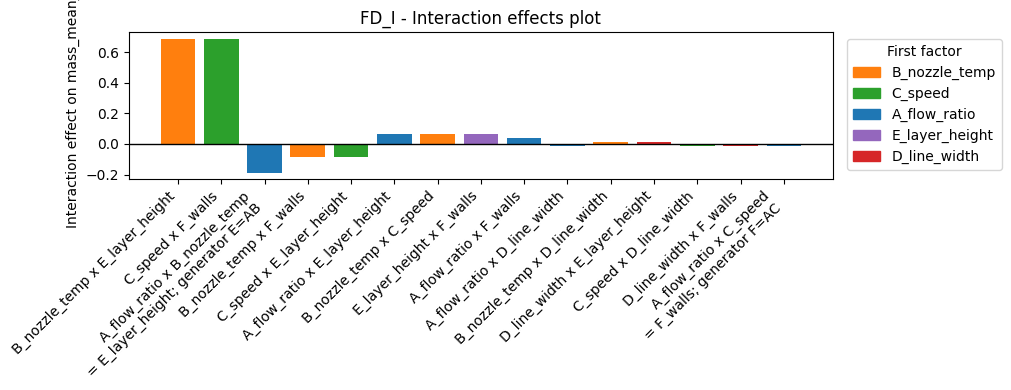

In [31]:
plot_interaction_effects(
    interaction_effects_I,
    experiment="FD_I",
)


### FD_II Screening Analysis


#### FD_II Main-Effect Estimates


In [32]:
mass_result_matrix_II = build_result_matrix(
    fd_II_coded_df,
    mass_measurements_g,
    response="mass_mean_g",
)
#mass_result_matrix_II


In [33]:
main_effect_df = compute_main_effects(mass_result_matrix_II, response="mass_mean_g")
main_effect_df


,Effect,Main effect
0,A_flow_ratio,3.625
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


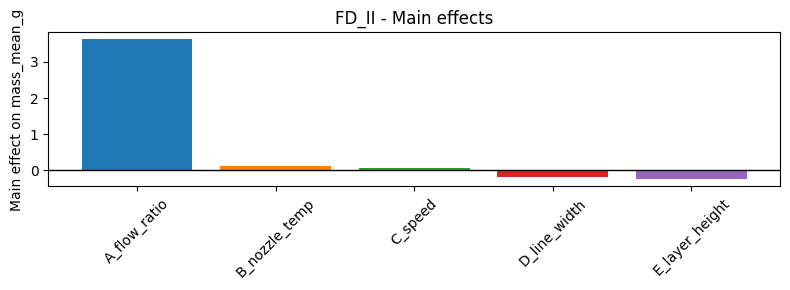

In [34]:
plot_main_effects_bar(
    main_effect_df,
    response="mass_mean_g",
    experiment="FD_II",
)


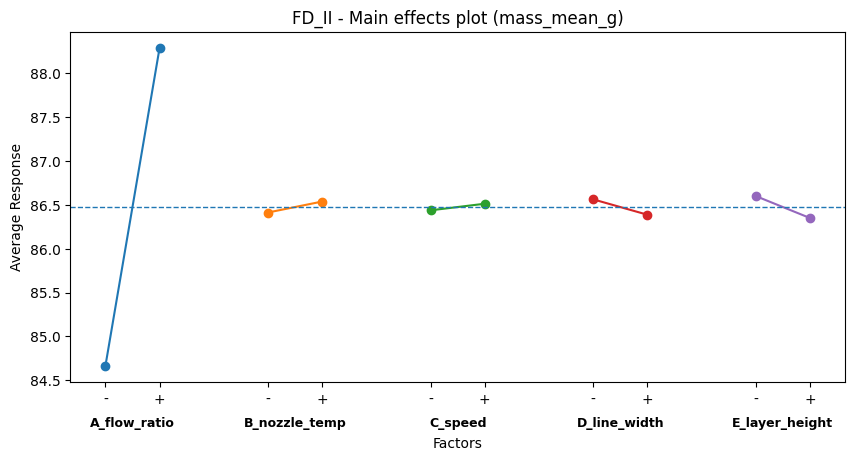

In [35]:
plot_main_effects_line(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Main-Effect Estimates Excluding Flow Ratio


In [36]:
main_effect_df_no_flow = main_effect_df[
    main_effect_df["Effect"] != "A_flow_ratio"
].copy()

mass_result_matrix_II_no_flow = mass_result_matrix_II.drop(
    columns=["A_flow_ratio"]
)

main_effect_df_no_flow


,Effect,Main effect
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


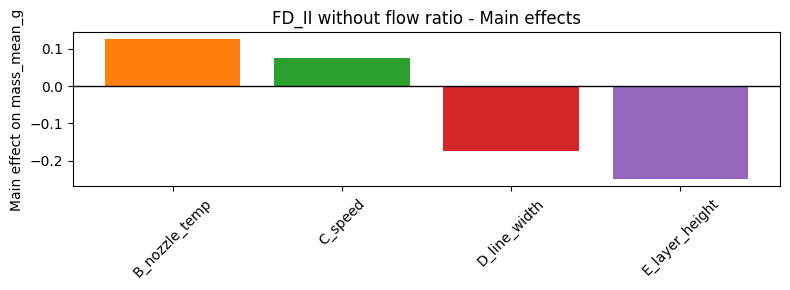

In [37]:
plot_main_effects_bar(
    main_effect_df_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


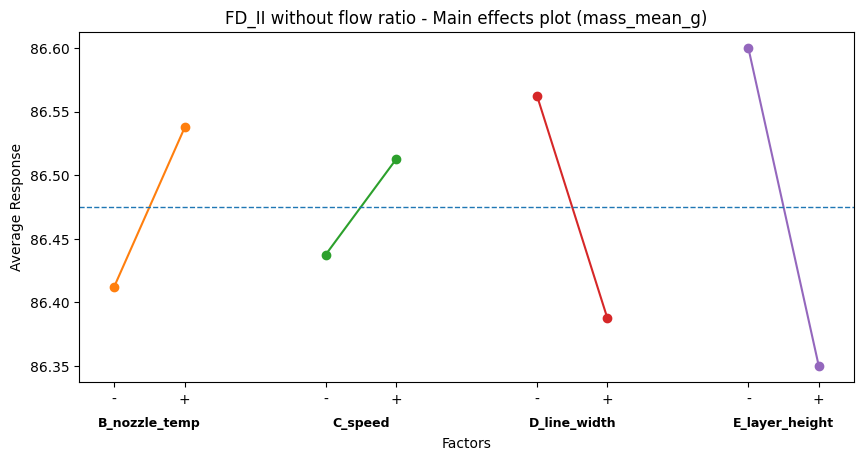

In [38]:
plot_main_effects_line(
    mass_result_matrix_II_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


#### FD_II Aliased Interaction Estimates


In [39]:
FD_II_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
}

interaction_effects_II = compute_interaction_effects(
    mass_result_matrix_II,
    response="mass_mean_g",
    generators=FD_II_GENERATORS,
)

interaction_effects_II


,Interaction,Alias / generator note,Effect
6,B_nozzle_temp x E_layer_height,,3.625000e+00
9,D_line_width x E_layer_height,,6.250000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.500000e-01
1,A_flow_ratio x C_speed,,2.000000e-01
2,A_flow_ratio x D_line_width,,2.000000e-01
3,A_flow_ratio x E_layer_height,,1.250000e-01
8,C_speed x E_layer_height,,-1.250000e-01
4,B_nozzle_temp x C_speed,,-1.000000e-01
5,B_nozzle_temp x D_line_width,,1.000000e-01
7,C_speed x D_line_width,,1.421085e-14


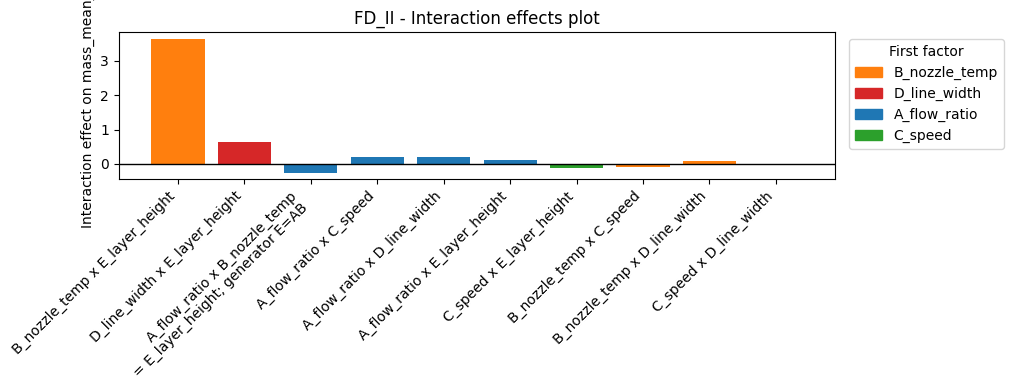

In [40]:
plot_interaction_effects(
    interaction_effects_II,
    experiment="FD_II",
)


#### FD_II Conditional Main Effects: Normal vs Overextrusion Runs


In [41]:
conditional_factor_cols = ["C_speed", "D_line_width"]

mass_result_matrix_II_RR1_8 = mass_result_matrix_II.iloc[:8][
    conditional_factor_cols + ["mass_mean_g"]
].copy()
mass_result_matrix_II_RR9_16 = mass_result_matrix_II.iloc[8:16][
    conditional_factor_cols + ["mass_mean_g"]
].copy()

conditional_effect_df_II_RR1_8 = compute_main_effects(
    mass_result_matrix_II_RR1_8,
    response="mass_mean_g",
)
conditional_effect_df_II_RR9_16 = compute_main_effects(
    mass_result_matrix_II_RR9_16,
    response="mass_mean_g",
)

display(conditional_effect_df_II_RR1_8)
display(conditional_effect_df_II_RR9_16)


,Effect,Main effect
0,C_speed,-0.125
1,D_line_width,-0.375


,Effect,Main effect
0,C_speed,0.275
1,D_line_width,0.025


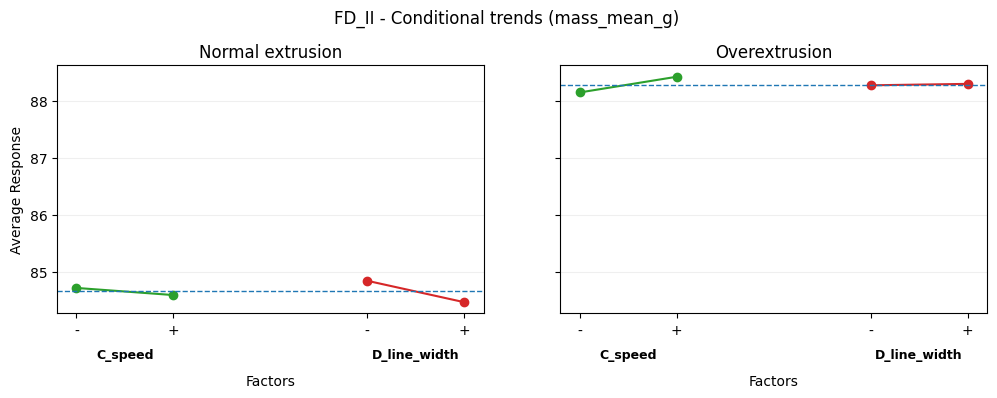

In [42]:
plot_main_effects_line_comparison(
    [mass_result_matrix_II_RR1_8, mass_result_matrix_II_RR9_16],
    labels=["Normal extrusion", "Overextrusion"],
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Main-Effect Prediction For E1 Confirmation Run


This comparison uses the additive main-effect model from FD_II. The prediction is calculated as `predicted mass = grand mean + sum(coded factor level * main effect / 2)`. E1 is used as the confirmation run for the main-effect maximum setting, so the predicted value comes from the FD_II screening model and the observed value comes from the measured E1 mass.


In [43]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

# E1 uses the best-looking FD_II settings from the main effects:
# high flow/nozzle temperature and low speed/line width/layer height.
E1_CODED_SETTING = {
    "A_flow_ratio": 1,
    "B_nozzle_temp": 1,
    "C_speed": -1,
    "D_line_width": -1,
    "E_layer_height": -1,
}

fd_II_mass_prediction_comparison = build_main_effect_prediction_comparison(
    mass_result_matrix_II,
    main_effect_df,
    FD_II_LEVELS,
    factor_cols=FD_II_FACTOR_COLUMNS,
    run_prefix="RR",
    experiment="FD_II",
    confirmation_measurements=extra_run_mass_measurements_g,
    confirmation_run="E1",
    confirmation_coded_setting=E1_CODED_SETTING,
    include_screening_rows=False,
)

display(fd_II_mass_prediction_comparison)


,case,coded_setting,real_setting,predicted_mass_g,observed_mass_g,note
0,E1 confirmation run,"{'A_flow_ratio': 1, 'B_nozzle_temp': 1, 'C_spe...","{'A_flow_ratio': 1.05, 'B_nozzle_temp': 230, '...",88.52,86.9,Predicted mass uses the FD_II main-effect maxi...


### Box-Behnken Response-Surface Analysis


The surface/contour plots visualize the fitted quadratic model. Each figure shows two factors changing across their real setting range while the third factor is held at the middle level. The 3D-style surface shows the predicted mass height; the 2D contour plot is the same surface viewed from above, where contour lines connect settings with equal predicted mass. Red points mark measured runs that lie on that slice.


The Box-Behnken analysis below uses only the new mass measurements. A quadratic response-surface model is fitted as `mass = b0 + b1*x1 + b2*x2 + b3*x3 + b11*x1^2 + b22*x2^2 + b33*x3^2 + b12*x1*x2 + b13*x1*x3 + b23*x2*x3`, where the `x` values are the coded factor levels. The center-point repeats estimate print-to-print repeatability at identical settings.


In [44]:
if "extra_run_15_coded" not in globals():
    EXTRA_RUN_BOX_BEHNKEN_LEVELS = {
        "B_nozzle_temp": {-1: 225, 0: 230, 1: 235},
        "D_line_width": {-1: 0.62, 0: 0.70, 1: 0.80},
        "E_layer_height": {-1: 0.10, 0: 0.12, 1: 0.14},
    }
    extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
        EXTRA_RUN_BOX_BEHNKEN_LEVELS,
        center_repeats=3,
    )

if "box_behnken_mass_measurements_g" not in globals():
    box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
        BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
        run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    )

box_behnken_result_matrix = build_result_matrix(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_result_matrix.dropna(subset=["mass_mean_g"]))


,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g
Run,,,,
1,0,-1,-1,89.1
2,0,-1,1,89.0
3,0,1,-1,89.0
4,0,1,1,89.2
5,-1,0,-1,89.3
6,-1,0,1,89.8
7,1,0,-1,89.7
8,1,0,1,89.3
9,-1,-1,0,88.9


,B_nozzle_temp,D_line_width,E_layer_height,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,
13,0,0,0,B13,88.8,0.000,-0.067,0.067
14,0,0,0,B14,88.9,0.006,0.033,0.033
15,0,0,0,B15,88.9,0.009,0.033,0.033


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,88.867,0.058,0.1,0.1,0.11,0.005


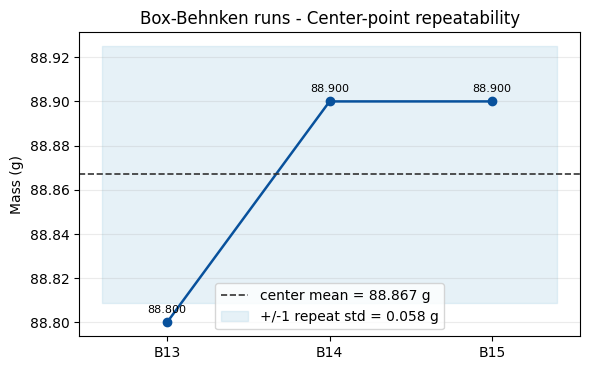

In [45]:
box_behnken_center_repeatability, box_behnken_repeatability_summary = calculate_center_point_repeatability(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_center_repeatability)
display(box_behnken_repeatability_summary)

plot_center_point_repeatability(
    box_behnken_center_repeatability,
    box_behnken_repeatability_summary,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)


The ANOVA table separates the variation explained by the quadratic Box-Behnken model from the unexplained residual variation. The Pareto plot ranks the fitted linear, quadratic, and interaction terms by their absolute standardized effect, so longer bars indicate terms that are more influential relative to the residual scatter.


In [46]:
box_behnken_mass_model = fit_quadratic_response_surface(
    box_behnken_result_matrix,
    response="mass_mean_g",
)

display(box_behnken_mass_model["info_df"].round(4))
display(box_behnken_mass_model["coefficient_df"].round(4))
display(box_behnken_mass_model["fitted_df"].round(3))

box_behnken_anova_table = build_quadratic_anova_table(box_behnken_mass_model)
display(box_behnken_anova_table.round(4))
display(box_behnken_mass_model["term_statistics_df"].round(4))


,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,15,10,10,5,0.9482,0.1258


,term,coefficient
0,Intercept,88.8667
1,B_nozzle_temp,-0.0625
2,D_line_width,0.1125
3,E_layer_height,0.0250
4,B_nozzle_temp^2,0.2417
5,D_line_width^2,-0.2083
6,E_layer_height^2,0.4167
7,B_nozzle_temp:D_line_width,0.1000
8,B_nozzle_temp:E_layer_height,-0.2250
9,D_line_width:E_layer_height,0.0750


,run,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,1,0,-1,-1,89.1,89.012,0.088
2,2,0,-1,1,89.0,88.912,0.088
3,3,0,1,-1,89.0,89.087,-0.087
4,4,0,1,1,89.2,89.288,-0.087
5,5,-1,0,-1,89.3,89.337,-0.037
6,6,-1,0,1,89.8,89.838,-0.038
7,7,1,0,-1,89.7,89.662,0.038
8,8,1,0,1,89.3,89.262,0.038
9,9,-1,-1,0,88.9,88.950,-0.050


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,9,1.4502,0.1611,10.1766,0.01
1,Residual,5,0.0792,0.0158,NaN,NaN
2,Total,14,1.5293,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,absolute_t_value,F_value,p_value
0,Intercept,88.8667,0.0726,1223.2447,1223.2447,1.496328e+06,0.0000
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.4049,1.973700e+00,0.2190
2,D_line_width,0.1125,0.0445,2.5288,2.5288,6.394700e+00,0.0526
3,E_layer_height,0.0250,0.0445,0.5620,0.5620,3.158000e-01,0.5984
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,3.6905,1.361940e+01,0.0141
5,D_line_width^2,-0.2083,0.0655,-3.1814,3.1814,1.012150e+01,0.0245
6,E_layer_height^2,0.4167,0.0655,6.3628,6.3628,4.048580e+01,0.0014
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,1.5894,2.526300e+00,0.1728
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,3.5762,1.278950e+01,0.0159
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.1921,1.421100e+00,0.2867


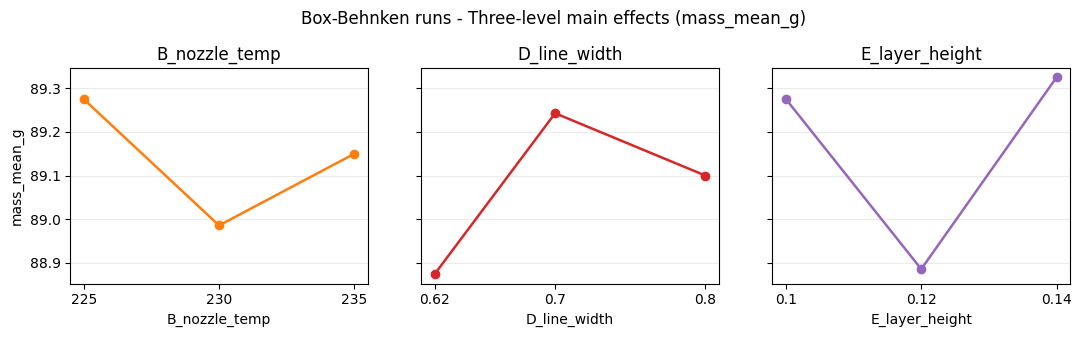

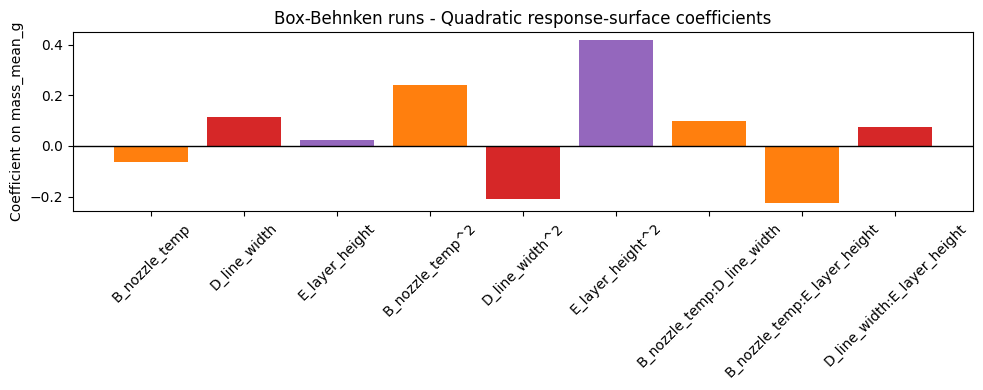

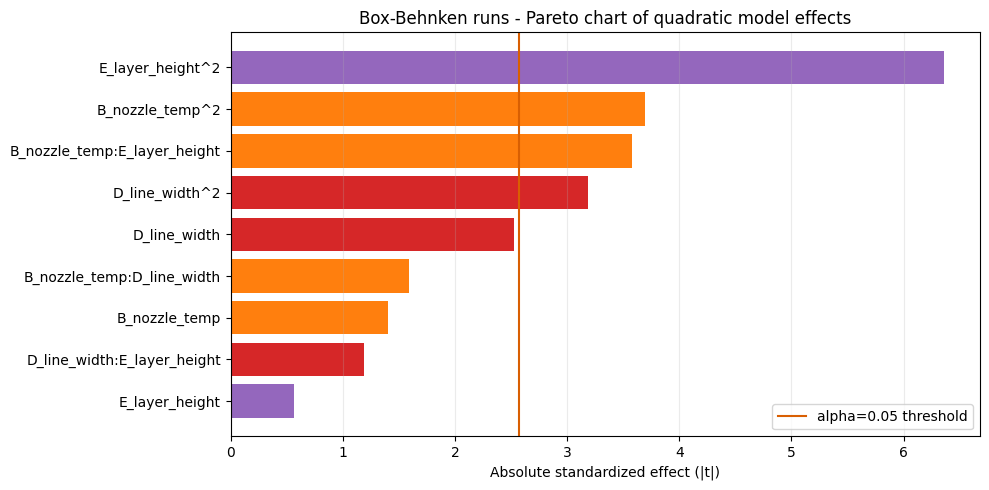

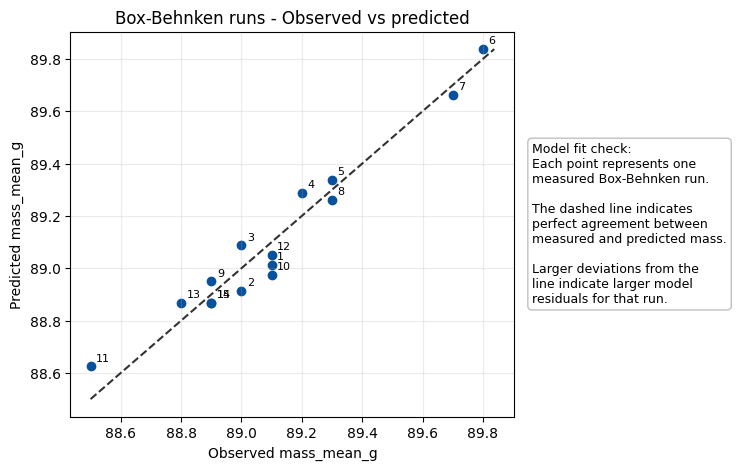

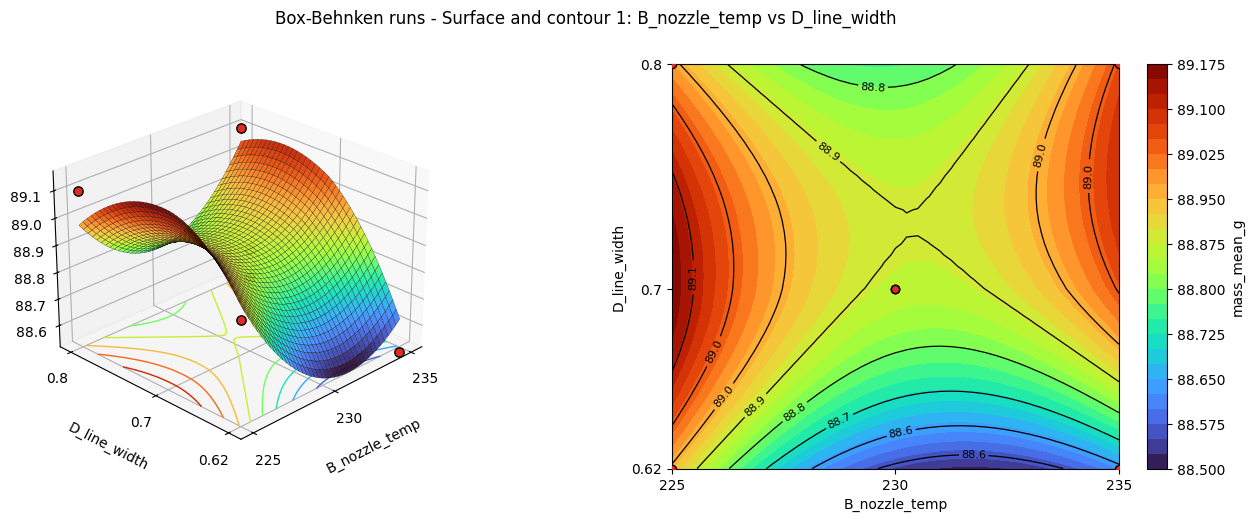

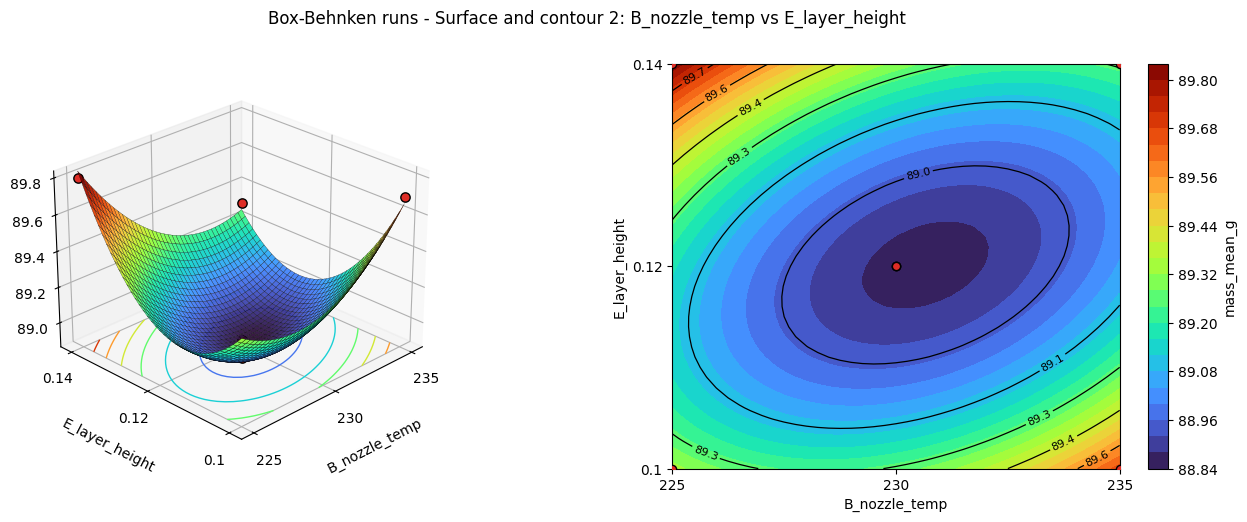

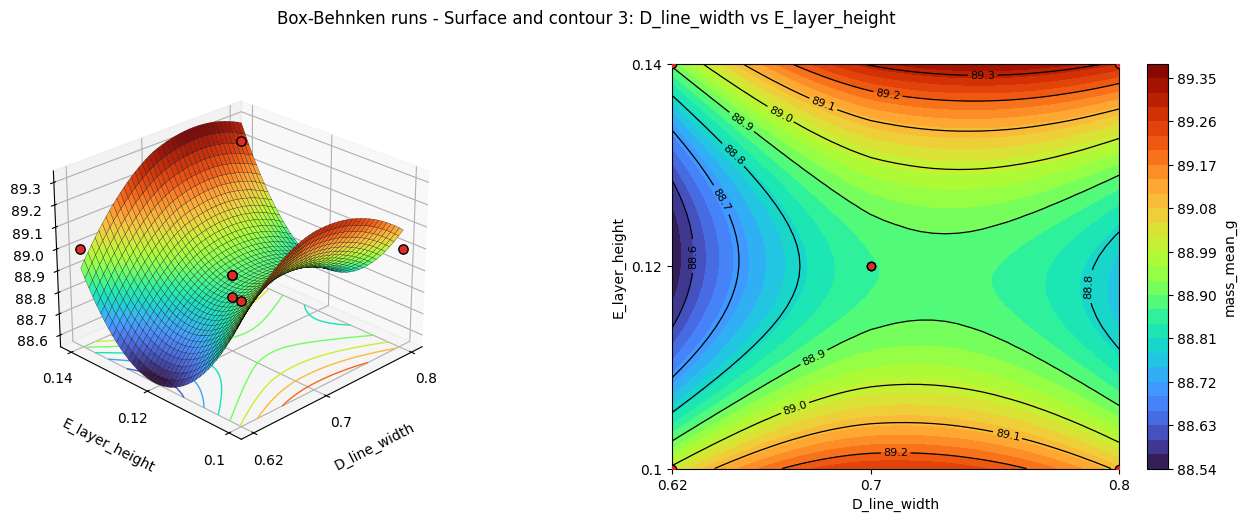

In [47]:
plot_three_level_main_effects(
    box_behnken_result_matrix,
    response="mass_mean_g",
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    experiment="Box-Behnken runs",
)

plot_quadratic_coefficients(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_pareto(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_observed_vs_predicted(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_surface_and_contour_pairs(
    box_behnken_mass_model,
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    fixed_level=0,
    experiment="Box-Behnken runs",
)


### Ironing Screening Analysis


This analysis uses the measured ironing runs to estimate the main effects and the aliased interaction pairs from the half-fraction design. A positive main effect means the response increases when the factor moves from its low coded level (-1) to its high coded level (+1); a negative main effect means the response decreases. The three center runs I9-I11 are still used separately for repeatability and overall curvature. A full quadratic response surface is not estimable from this 11-run, 4-factor half fraction: it would require 15 coefficients, and the individual squared terms are aliased in a two-level design. The center-point check below can detect only combined curvature, not which factor causes it.


In [48]:
ironing_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_mass_measurements_g,
    response="mass_mean_g",
)

ironing_result_matrix_with_data = ironing_result_matrix.dropna(
    subset=["mass_mean_g"]
)
print(
    f"Available ironing measurements: "
    f"{len(ironing_result_matrix_with_data)}/{len(ironing_result_matrix)}"
)
display(ironing_result_matrix_with_data)

ironing_level_coverage = build_factor_level_coverage(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)
display(
    ironing_level_coverage.pivot(
        index="factor",
        columns="coded_level",
        values="available_runs",
    ).rename(columns={-1: "low (-1)", 0: "center (0)", 1: "high (+1)"})
)


Available ironing measurements: 11/11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g
Run,,,,,
1,-1,-1,-1,-1,9.45
2,-1,-1,1,1,9.62
3,-1,1,-1,1,9.48
4,-1,1,1,-1,9.54
5,1,-1,-1,1,9.55
6,1,-1,1,-1,9.68
7,1,1,-1,-1,9.56
8,1,1,1,1,9.72
9,0,0,0,0,9.50


coded_level,low (-1),center (0),high (+1)
factor,,,
A_flow_ratio,4,3,4
B_nozzle_temp_C,4,3,4
C_ironing_flow_percent,4,3,4
D_ironing_speed_mm_s,4,3,4


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.6841,0.067


,term,coefficient,effect,standard_error,t_value,p_value
0,Intercept,9.5473,9.5473,0.0202,472.7466,0.0000
1,A_flow_ratio,0.0525,0.1050,0.0237,2.2170,0.0685
2,B_nozzle_temp_C,0.0000,0.0000,0.0237,0.0000,1.0000
3,C_ironing_flow_percent,0.0650,0.1300,0.0237,2.7448,0.0335
4,D_ironing_speed_mm_s,0.0175,0.0350,0.0237,0.7390,0.4878


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,9.45,9.412,0.038
2,-1,-1,1,1,9.62,9.577,0.043
3,-1,1,-1,1,9.48,9.447,0.033
4,-1,1,1,-1,9.54,9.542,-0.002
5,1,-1,-1,1,9.55,9.552,-0.002
6,1,-1,1,-1,9.68,9.647,0.033
7,1,1,-1,-1,9.56,9.517,0.043
8,1,1,1,1,9.72,9.682,0.038
9,0,0,0,0,9.50,9.547,-0.047


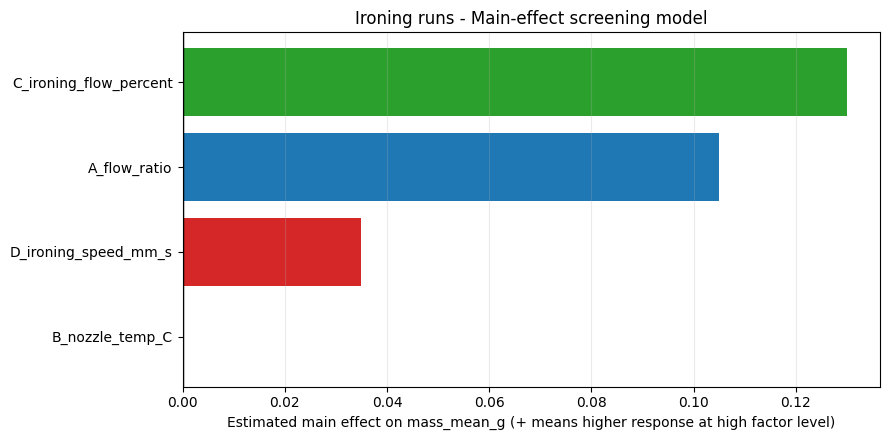

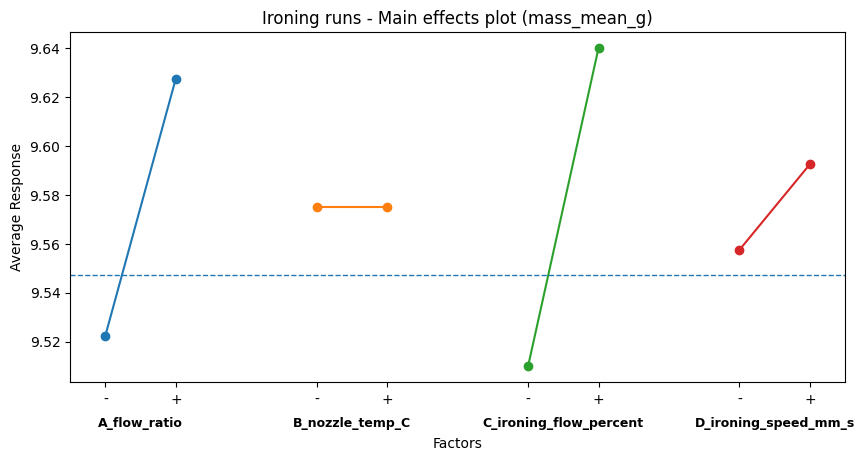

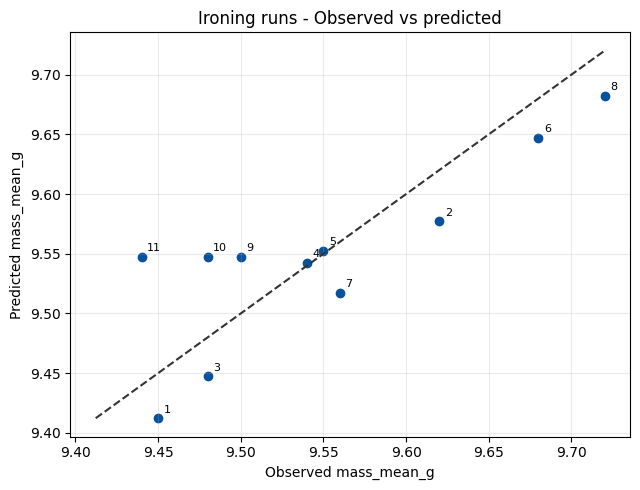

In [49]:
ironing_main_effect_model = fit_main_effect_screening_model(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_main_effect_model["info_df"].round(4))
display(ironing_main_effect_model["statistics_df"].round(4))
display(ironing_main_effect_model["fitted_df"].round(3))

if ironing_main_effect_model["info_df"].loc[0, "full_rank"]:
    plot_screening_model_effects(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
    plot_main_effects_line(
        ironing_result_matrix_with_data,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
    plot_screening_observed_vs_predicted(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
else:
    print(
        "The available measurements do not yet provide a full-rank main-effects model. "
        "Add runs with missing factor-level combinations."
    )


#### IA and IB Confirmation-Run Comparison


The fitted ironing main-effect model predicts IA and IB from their coded settings. `prediction_error = observed mass - predicted mass`; a small absolute error supports the additive model at these mixed-level settings. IB stringing is retained as a qualitative warning and is not converted into a blob score because no blob count was supplied.


,run,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,quality_score,has_stringing,A_flow_ratio_coded,B_nozzle_temp_C_coded,C_ironing_flow_percent_coded,D_ironing_speed_mm_s_coded,predicted_response,prediction_error,abs_prediction_error
0,IA,1.01,220,2,60,9.650,2.5,False,1.0,0.0,1.0,1.0,9.682,-0.032,0.032
1,IB,1.01,220,2,45,9.627,8.0,True,1.0,0.0,1.0,0.0,9.665,-0.038,0.038


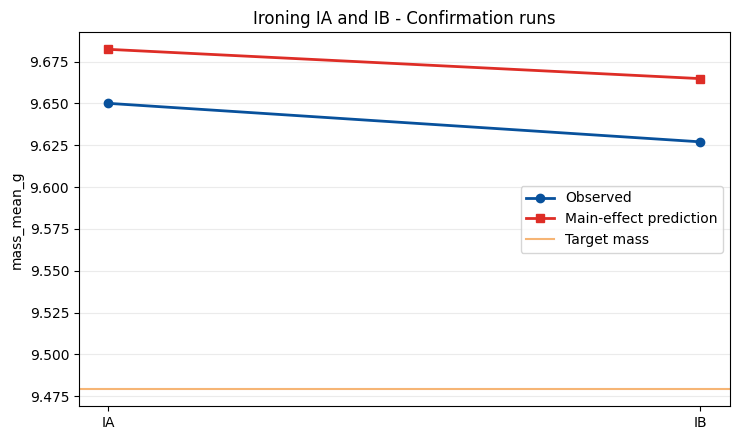

,run,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,quality_score,has_stringing,design_role
0,I1,-1.0,-1.0,-1.0,-1.0,9.450,7.0,False,original half-fraction / center
1,I2,-1.0,-1.0,1.0,1.0,9.620,11.0,False,original half-fraction / center
2,I3,-1.0,1.0,-1.0,1.0,9.480,2.0,False,original half-fraction / center
3,I4,-1.0,1.0,1.0,-1.0,9.540,3.0,False,original half-fraction / center
4,I5,1.0,-1.0,-1.0,1.0,9.550,6.0,False,original half-fraction / center
5,I6,1.0,-1.0,1.0,-1.0,9.680,15.0,True,original half-fraction / center
6,I7,1.0,1.0,-1.0,-1.0,9.560,1.0,False,original half-fraction / center
7,I8,1.0,1.0,1.0,1.0,9.720,1.0,False,original half-fraction / center
8,I9,0.0,0.0,0.0,0.0,9.500,2.0,False,original half-fraction / center
9,I10,0.0,0.0,0.0,0.0,9.480,2.0,False,original half-fraction / center


In [50]:
ironing_confirmation_comparison = build_screening_confirmation_comparison(
    ironing_main_effect_model,
    ironing_confirmation_runs,
    IRONING_LEVELS,
    response="mass_mean_g",
)

display(ironing_confirmation_comparison.round(3))
plot_screening_confirmation_comparison(
    ironing_confirmation_comparison,
    response="mass_mean_g",
    target_value=ideal_mass_ironing_g,
    experiment="Ironing IA and IB",
)

# Append IA and IB for comparison and future augmented modeling.
ironing_design_matrix_labeled = ironing_result_matrix.copy()
ironing_design_matrix_labeled.insert(0, "run", IRONING_RUN_LABELS)
ironing_design_matrix_labeled["quality_score"] = ironing_quality_table[
    "quality_score"
].to_numpy()
ironing_design_matrix_labeled["has_stringing"] = ironing_quality_table[
    "has_stringing"
].to_numpy()
ironing_design_matrix_labeled["design_role"] = "original half-fraction / center"

ironing_confirmation_matrix = pd.DataFrame({
    "run": ironing_confirmation_comparison["run"],
    **{
        factor: ironing_confirmation_comparison[f"{factor}_coded"]
        for factor in IRONING_LEVELS
    },
    "mass_mean_g": ironing_confirmation_comparison["mass_mean_g"],
    "quality_score": ironing_confirmation_comparison["quality_score"],
    "has_stringing": ironing_confirmation_comparison["has_stringing"],
    "design_role": "additional confirmation",
})

ironing_augmented_matrix = pd.concat(
    [ironing_design_matrix_labeled, ironing_confirmation_matrix],
    ignore_index=True,
    sort=False,
)
display(ironing_augmented_matrix)


#### Ironing Visual-Quality Screening


This repeats the same screening analysis with `quality_score` as the response. For this response, positive effects are unfavorable because they mean more blobs/stringing at the high factor level; negative effects are favorable because they reduce the defect score.


The combined optimization below uses the weighted geometric mean of two desirabilities: mass is higher-is-better and visual defect score is lower-is-better. With equal weights, `D = sqrt(d_mass * d_quality)`. A zero desirability for either response makes the overall desirability zero. The current limits use the observed minimum and maximum and should later be replaced by engineering acceptance limits if available.


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score
Run,,,,,
1,-1,-1,-1,-1,7
2,-1,-1,1,1,11
3,-1,1,-1,1,2
4,-1,1,1,-1,3
5,1,-1,-1,1,6
6,1,-1,1,-1,15
7,1,1,-1,-1,1
8,1,1,1,1,1
9,0,0,0,0,2


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.7561,2.9051


,term,coefficient,effect,standard_error,t_value,p_value
0,Intercept,4.8182,4.8182,0.8759,5.5008,0.0015
1,A_flow_ratio,0.0000,0.0000,1.0271,0.0000,1.0000
2,B_nozzle_temp_C,-4.0000,-8.0000,1.0271,-3.8945,0.0080
3,C_ironing_flow_percent,1.7500,3.5000,1.0271,1.7038,0.1393
4,D_ironing_speed_mm_s,-0.7500,-1.5000,1.0271,-0.7302,0.4928


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,7,7.818,-0.818
2,-1,-1,1,1,11,9.818,1.182
3,-1,1,-1,1,2,-1.682,3.682
4,-1,1,1,-1,3,3.318,-0.318
5,1,-1,-1,1,6,6.318,-0.318
6,1,-1,1,-1,15,11.318,3.682
7,1,1,-1,-1,1,-0.182,1.182
8,1,1,1,1,1,1.818,-0.818
9,0,0,0,0,2,4.818,-2.818


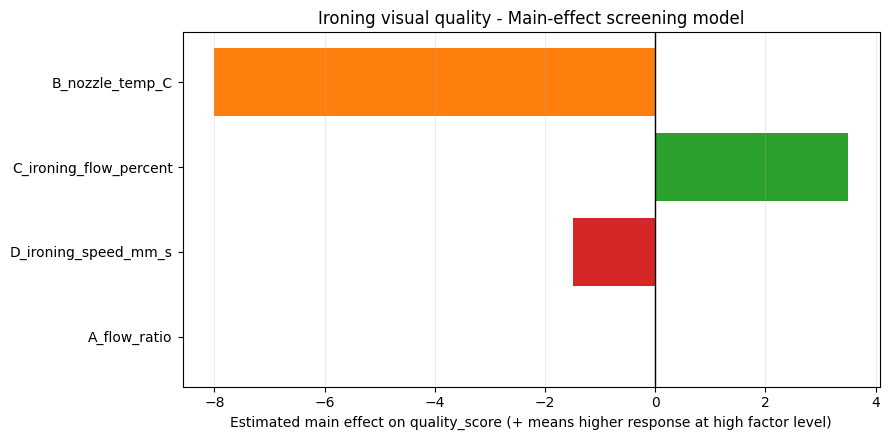

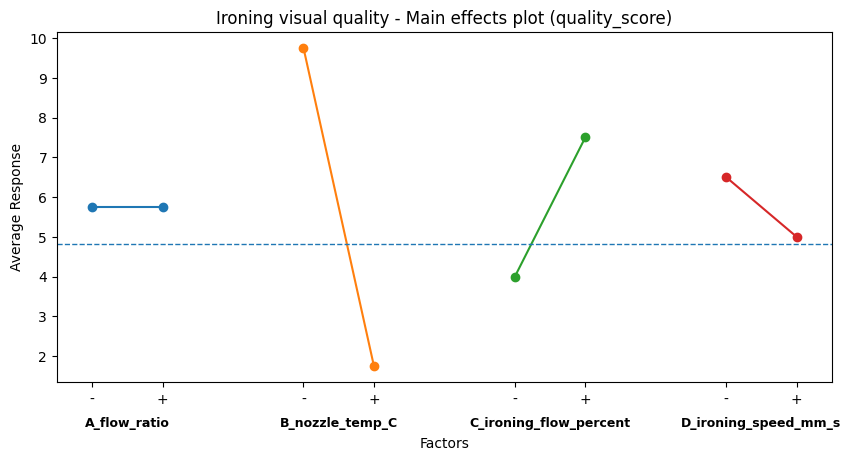

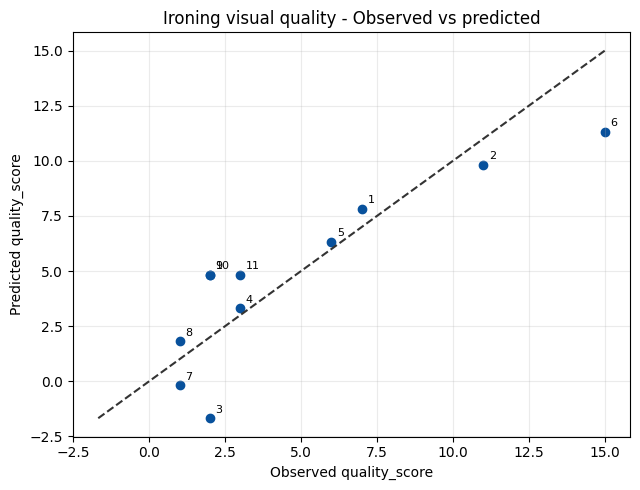

,run,mass_mean_g,quality_score,mass_desirability,quality_desirability,overall_desirability,desirability_rank
8,I8,9.720,1.0,1.000,1.000,1.000,1.0
11,IA,9.650,2.5,0.750,0.893,0.818,2.0
4,I7,9.560,1.0,0.429,1.000,0.655,3.0
12,IB,9.627,8.0,0.668,0.500,0.578,4.0
5,I4,9.540,3.0,0.357,0.857,0.553,5.0
7,I5,9.550,6.0,0.393,0.643,0.503,6.0
2,I9,9.500,2.0,0.214,0.929,0.446,7.0
9,I2,9.620,11.0,0.643,0.286,0.429,8.0
0,I10,9.480,2.0,0.143,0.929,0.364,9.0
1,I3,9.480,2.0,0.143,0.929,0.364,9.0


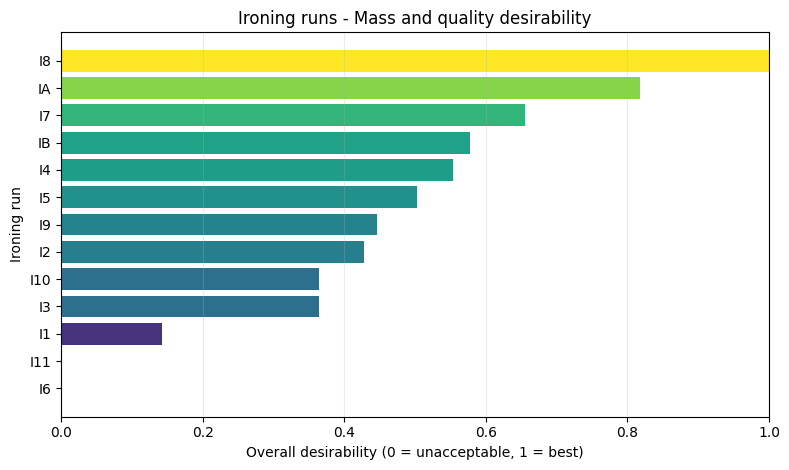

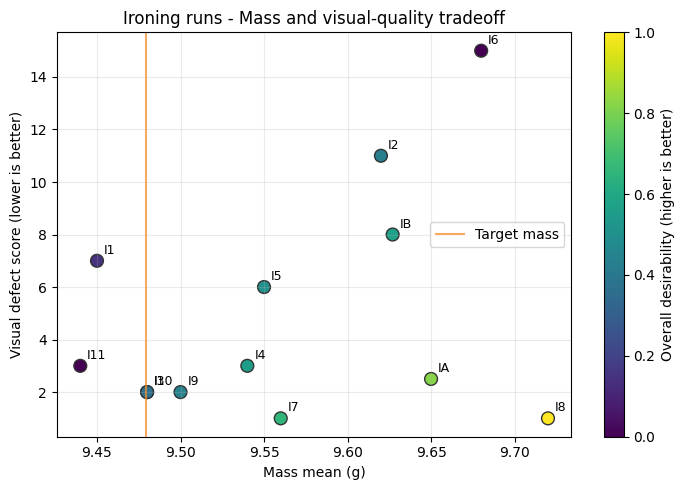

In [51]:
ironing_quality_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_quality_table,
    response="quality_score",
)
ironing_quality_result_matrix_with_data = ironing_quality_result_matrix.dropna(
    subset=["quality_score"]
)

display(ironing_quality_result_matrix_with_data)

ironing_quality_model = fit_main_effect_screening_model(
    ironing_quality_result_matrix,
    response="quality_score",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_quality_model["info_df"].round(4))
display(ironing_quality_model["statistics_df"].round(4))
display(ironing_quality_model["fitted_df"].round(3))

if ironing_quality_model["info_df"].loc[0, "full_rank"]:
    plot_screening_model_effects(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
    plot_main_effects_line(
        ironing_quality_result_matrix_with_data,
        response="quality_score",
        experiment="Ironing visual quality",
    )
    plot_screening_observed_vs_predicted(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
else:
    print("The visual-quality measurements do not provide a full-rank main-effects model yet.")

# Limits are based on the observed ironing runs and can be replaced by
# engineering acceptance limits when those are defined.
MASS_DESIRABILITY_LOW = ironing_mass_quality_tradeoff["mass_mean_g"].min()
MASS_DESIRABILITY_HIGH = ironing_mass_quality_tradeoff["mass_mean_g"].max()
QUALITY_DESIRABILITY_BEST = ironing_mass_quality_tradeoff["quality_score"].min()
QUALITY_DESIRABILITY_WORST = ironing_mass_quality_tradeoff["quality_score"].max()

ironing_desirability = build_desirability_table(
    ironing_mass_quality_tradeoff,
    mass_low=MASS_DESIRABILITY_LOW,
    mass_high=MASS_DESIRABILITY_HIGH,
    quality_best=QUALITY_DESIRABILITY_BEST,
    quality_worst=QUALITY_DESIRABILITY_WORST,
    mass_weight=1.0,
    quality_weight=1.0,
)

display(ironing_desirability[[
    "run",
    "mass_mean_g",
    "quality_score",
    "mass_desirability",
    "quality_desirability",
    "overall_desirability",
    "desirability_rank",
]].round(3))

plot_desirability_ranking(
    ironing_desirability,
    experiment="Ironing runs",
)
plot_mass_quality_tradeoff(
    ironing_desirability,
    target_mass_g=ideal_mass_ironing_g,
    experiment="Ironing runs",
)


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,9.473,0.031,0.06,0.06,0.63,NaN


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,,
9,0,0,0,0,I9,9.50,NaN,0.027,0.027
10,0,0,0,0,I10,9.48,NaN,0.007,0.007
11,0,0,0,0,I11,9.44,NaN,-0.033,0.033


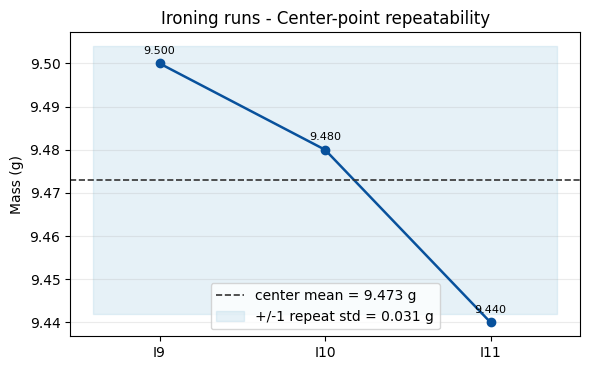

In [52]:
ironing_center_repeatability, ironing_center_repeatability_summary = (
    calculate_center_point_repeatability(
        ironing_coded,
        ironing_mass_measurements_g,
        response="mass_mean_g",
    )
)

display(ironing_center_repeatability_summary)
if not ironing_center_repeatability.empty:
    display(ironing_center_repeatability)
    plot_center_point_repeatability(
        ironing_center_repeatability,
        ironing_center_repeatability_summary,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
else:
    print("Center-point repeatability will be available after measuring I9-I11.")


#### Ironing Overall Curvature Check


,factorial_runs_with_data,center_runs_with_data,factorial_mean_g,center_mean_g,overall_curvature_g,center_std_g
0,8,3,9.575,9.4733,-0.1017,0.0306


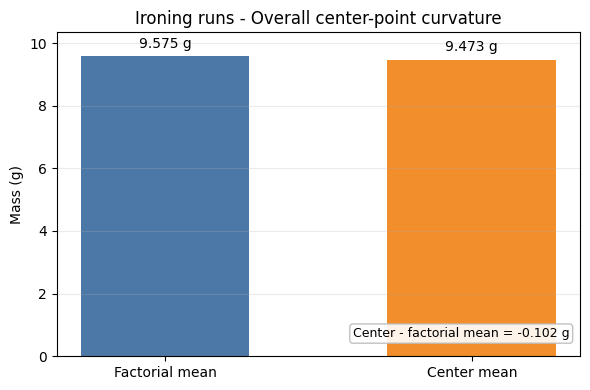

In [53]:
ironing_curvature_summary = calculate_center_curvature(
    ironing_coded,
    ironing_mass_measurements_g,
    response="mass_mean_g",
)
display(ironing_curvature_summary.round(4))

if ironing_curvature_summary.loc[0, "center_runs_with_data"] > 0:
    plot_center_curvature(
        ironing_curvature_summary,
        experiment="Ironing runs",
    )
else:
    print(
        "Overall curvature will be available after at least one center run is measured. "
        "Measuring all I9-I11 is recommended so center repeatability can also be estimated."
    )


Measured factorial corners: 8/8


,Interaction,Alias / generator note,Effect
0,A_flow_ratio x B_nozzle_temp_C,,0.025
5,C_ironing_flow_percent x D_ironing_speed_mm_s,,0.025
3,B_nozzle_temp_C x C_ironing_flow_percent,,-0.020
2,A_flow_ratio x D_ironing_speed_mm_s,,-0.020
1,A_flow_ratio x C_ironing_flow_percent,,0.015
4,B_nozzle_temp_C x D_ironing_speed_mm_s,,0.015


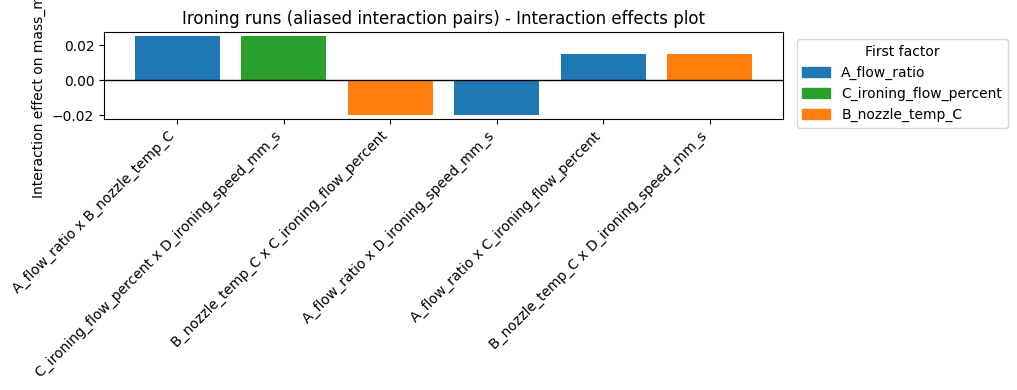

In [54]:
ironing_factorial_mask = ironing_result_matrix[list(IRONING_LEVELS)].abs().eq(1).all(axis=1)
ironing_factorial_with_data = ironing_result_matrix.loc[
    ironing_factorial_mask
].dropna(subset=["mass_mean_g"])

print(
    f"Measured factorial corners: {len(ironing_factorial_with_data)}/8"
)
if len(ironing_factorial_with_data) == 8:
    ironing_interaction_effects = compute_interaction_effects(
        ironing_factorial_with_data,
        response="mass_mean_g",
    )
    display(ironing_interaction_effects)
    plot_interaction_effects(
        ironing_interaction_effects,
        experiment="Ironing runs (aliased interaction pairs)",
    )
else:
    print(
        "Interaction estimates are deferred until all 8 factorial corners are measured. "
        "The interaction pairs will remain aliased: AB=CD, AC=BD, AD=BC."
    )
